# Loading Datasets

In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np
import scienceplots
import umap

# This is for all the sets
model_location = r'outer_functions/DimRed_data/model.xlsx'

sampleName_Dict={
                    
                    #OK
                   "Intensity CtrlminusFBS_0m_Rep1": "Ctrl-FBS 0m (1)",
                    #OK
                   "Intensity FGF2plusFBS_30m_Rep1": "FGF2+FBS 30m (1)",
                    #OK
                   "Intensity CtrlminusFBS_30m_Rep2": "Ctrl-FBS 30m (2)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_10m_Rep2": "SOSi/FGF2+FBS 10m (2)",
                    #OK
                   "Intensity FGF2minusFBS_10m_Rep3": "FGF2-FBS 10m (3)",
                    #OK
                   "Intensity CtrlplusFBS_0m_Rep1": "Ctrl+FBS 0m (1)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_5s_Rep1": "SOSi/FGF2-FBS 5s (1)",
                    #OK
                   "Intensity CtrlplusFBS_30m_Rep2": "Ctrl+FBS 30m (2)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_30m_Rep2": "SOSi/FGF2-FBS 30m (2)",
                    #OK
                   "Intensity FGF2plusFBS_10m_Rep3": "FGF2+FBS 10m (3)",
                    #OK
                   "Intensity CtrlminusFBS_5m_Rep1": "Ctrl-FBS 5m (1)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_5s_Rep1": "SOSi/FGF2+FBS 5s (1)",
                    #OK
                   "Intensity FGF2minusFBS_5s_Rep2": "FGF2-FBS 5s (2)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_30m_Rep2": "SOSi/FGF2+FBS 30m (2)",
                    #OK
                   "Intensity FGF2minusFBS_30m_Rep3": "FGF2-FBS 30m (3)",
                    #OK
                   "Intensity CtrlplusFBS_5m_Rep1": "Ctrl+FBS 5m (1)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_5m_Rep1": "SOSi/FGF2-FBS 5m (1)",
                    #OK
                   "Intensity FGF2plusFBS_5s_Rep2": "FGF2+FBS 5s (2)",
                    #OK
                   "Intensity CtrlminusFBS_0m_Rep3": "Ctrl-FBS 0m (3)",
                    #OK
                   "Intensity FGF2plusFBS_30m_Rep3": "FGF2+FBS 30m (3)",
                    #OK
                   "Intensity CtrlminusFBS_10m_Rep1": "Ctrl-FBS 10m (1)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_5m_Rep1": "SOSi/FGF2+FBS 5m (1)",
                    #OK
                   "Intensity FGF2minusFBS_5m_Rep2": "FGF2-FBS 5m (2)",
                    #OK
                   "Intensity CtrlplusFBS_0m_Rep3": "Ctrl+FBS 0m (3)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_5s_Rep3": "SOSi/FGF2-FBS 5s (3)",
                    #OK
                   "Intensity CtrlplusFBS_10m_Rep1": "Ctrl+FBS 10m (1)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_10m_Rep1": "SOSi/FGF2-FBS 10m (1)",
                    #OK
                   "Intensity FGF2plusFBS_5m_Rep2": "FGF2+FBS 5m (2)",
                    #OK
                   "Intensity CtrlminusFBS_5m_Rep3": "Ctrl-FBS 5m (3)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_5s_Rep3": "SOSi/FGF2+FBS 5s (3)",
                    #OK
                   "Intensity CtrlminusFBS_30m_Rep1": "Ctrl-FBS 30m (1)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_10m_Rep1": "SOSi/FGF2+FBS 10m (1)",
                    #OK
                   "Intensity FGF2minusFBS_10m_Rep2": "FGF2-FBS 10m (2)",
                    #OK
                   "Intensity CtrlplusFBS_5m_Rep3": "Ctrl+FBS 5m (3)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_5m_Rep3": "SOSi/FGF2-FBS 5m (3)",
                    #OK
                   "Intensity CtrlplusFBS_30m_Rep1": "Ctrl+FBS 30m (1)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_30m_Rep1": "SOSi/FGF2-FBS 30m (1)",
                    #OK
                   "Intensity FGF2plusFBS_10m_Rep2": "FGF2+FBS 10m (2)",
                    #OK
                   "Intensity CtrlminusFBS_10m_Rep3": "Ctrl-FBS 10m (3)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_5m_Rep3": "SOSi/FGF2+FBS 5m (3)",
                    #OK
                   "Intensity FGF2minusFBS_5s_Rep1": "FGF2-FBS 5s (1)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_30m_Rep1": "SOSi/FGF2+FBS 30m (1)",
                    #OK
                   "Intensity FGF2minusFBS_30m_Rep2": "FGF2-FBS 30m (2)",
                    #OK
                   "Intensity CtrlplusFBS_10m_Rep3": "Ctrl+FBS 10m (3)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_10m_Rep3": "SOSi/FGF2-FBS 10m (3)",
                    #OK
                   "Intensity FGF2plusFBS_5s_Rep1": "FGF2+FBS 5s (1)",
                    #OK
                   "Intensity CtrlminusFBS_0m_Rep2": "Ctrl-FBS 0m (2)",
                    #OK
                   "Intensity FGF2plusFBS_30m_Rep2": "FGF2+FBS 30m (2)",
                    #OK
                   "Intensity CtrlminusFBS_30m_Rep3": "Ctrl-FBS 30m (3)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_10m_Rep3": "SOSi/FGF2+FBS 10m (3)",
                    #OK
                   "Intensity FGF2minusFBS_5m_Rep1": "FGF2-FBS 5m (1)",
                    #OK
                   "Intensity CtrlplusFBS_0m_Rep2": "Ctrl+FBS 0m (2)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_5s_Rep2": "SOSi/FGF2-FBS 5s (2)",
                    #OK
                   "Intensity CtrlplusFBS_30m_Rep3": "Ctrl+FBS 30m (3)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_30m_Rep3": "SOSi/FGF2-FBS 30m (3)",
                    #OK
                   "Intensity FGF2plusFBS_5m_Rep1": "FGF2+FBS 5m (1)",
                    #OK
                   "Intensity CtrlminusFBS_5m_Rep2": "Ctrl-FBS 5m (2)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_5s_Rep2": "SOSi/FGF2+FBS 5s (2)",
                    #OK
                   "Intensity FGF2minusFBS_5s_Rep3": "FGF2-FBS 5s (3)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_30m_Rep3": "SOSi/FGF2+FBS 30m (3)",
                    #OK
                   "Intensity FGF2minusFBS_10m_Rep1": "FGF2-FBS 10m (1)",
                    #OK
                   "Intensity CtrlplusFBS_5m_Rep2": "Ctrl+FBS 5m (2)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_5m_Rep2": "SOSi/FGF2-FBS 5m (2)",
                    #OK
                   "Intensity FGF2plusFBS_5s_Rep3": "FGF2+FBS 5s (3)",
                    #OK
                   "Intensity FGF2plusFBS_10m_Rep1": "FGF2+FBS 10m (1)",
                    #OK
                   "Intensity CtrlminusFBS_10m_Rep2": "Ctrl-FBS 10m (2)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_5m_Rep2": "SOSi/FGF2+FBS 5m (2)",
                    #OK
                   "Intensity FGF2minusFBS_5m_Rep3": "FGF2-FBS 5m (3)",
                    #OK
                   "Intensity FGF2minusFBS_30m_Rep1": "FGF2-FBS 30m (1)",
                    #OK
                   "Intensity CtrlplusFBS_10m_Rep2": "Ctrl+FBS 10m (2)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_10m_Rep2": "SOSi/FGF2-FBS 10m (2)",
                    #OK
                   "Intensity FGF2plusFBS_5m_Rep3": "FGF2+FBS 5m (3)",
                    #OK
                   "Intensity ref_Rep1": "Ref. Batch 1", 
                   #OK
                   "Intensity ref_Rep2": "Ref. Batch 2", 
                   #OK
                   "Intensity ref_Rep3": "Ref. Batch 3", 
                   #OK
                   "Intensity ref_Rep4": "Ref. Batch 4", 
                   #OK
                   "Intensity ref_Rep5": "Ref. Batch 5", 

                   }


# Phosphoproteome

# Before Combat
df_NoNorm_BeforeC = r'Phosphoproteome/output_files/01_Phospho_(STY)Sites_PIF_0.5_cleanLog2.tsv'

df_AfterC = r'Phosphoproteome/output_files/04_Phospho (STY)Sites_PIF_0.5_BPCA_ComBat_Centered_NoRef.tsv'

# Normal Proteome
df_np = r'Normal_Proteome/output_files/03_NormalProteome_result.pg_matrix_BPCA_Centered_DownstreamReady_CleanNames.tsv'




# Functions

## PCA

In [2]:

def PCA2d(
    experiment_name,
    model_file,       # Path to the model Excel file
    tsv_file,         # Path to the numerical data TSV file
    grouping,
    rename_dict=None,  # Dictionary mapping {old_name: new_name}
    output_path=None,
    fixed_size=(3,2),
    dpi=300,
    legend_ncol=None,
    pretty_batch_labels=True,
    legend_position="bottom"  # "bottom" or "right"
):
    # -------------------------
    # Load input files
    # -------------------------
    model = pd.read_excel(model_file, dtype=str)
    dataset = pd.read_csv(tsv_file, sep="\t", index_col=0)
    dataset = dataset.fillna(0)

    # Validate required columns in the model file
    required_cols = ['General', 'Batch', 'Condition', 'Replicate', 'Time']
    for col in required_cols:
        if col not in model.columns:
            raise ValueError(f"Column '{col}' missing in model file")

    # -------------------------
    # Rename sample columns if a dictionary is provided
    # -------------------------
    if rename_dict is not None:
        dataset.rename(columns=rename_dict, inplace=True)
        model['Replicate'] = model['Replicate'].map(lambda x: rename_dict.get(x, x))

    # Select dataset columns matching the samples listed in the model
    common_samples = model['Replicate'].values
    common_samples_existing = [c for c in common_samples if c in dataset.columns]
    if len(common_samples_existing) == 0:
        raise ValueError("After renaming, no matching columns found between model and dataset.")
    dataset = dataset.loc[:, common_samples_existing]

    # Reorder dataset columns to match the sample order in the model
    dataset = dataset[common_samples_existing]

    # -------------------------
    # Perform PCA
    # -------------------------
    pca = PCA(n_components=2)
    components = pca.fit_transform(dataset.T.astype(float))
    total_var = pca.explained_variance_ratio_.sum() * 100

    # -------------------------
    # Prepare grouping labels
    # -------------------------
    labels = model[grouping].astype(str)
    uniq = pd.Index(labels.values).unique()

    def _batch_num(s: str):
        s_low = s.lower().replace('_','').replace(' ','')
        m = re.search(r'(\d+)', s_low)
        if 'batch' in s_low and m:
            return int(m.group(1))
        return None

    is_batch_group = grouping.lower() == 'batch' and any(_batch_num(s) is not None for s in uniq)
    if is_batch_group:
        ordered_labels = sorted(uniq, key=lambda s: (_batch_num(s) is None, _batch_num(s) or 10**9))
    else:
        ordered_labels = list(uniq)

    # -------------------------
    # Define group colors
    # -------------------------
    vivid_colors = [
    "#e41a1c",  # Vibrant red
    "#377eb8",  # Vibrant blue
    "#4daf4a",  # Vibrant green
    "#984ea3",  # Purple
    "#ff7f00",  # Vibrant orange
    "#ffff33",  # Light yellow
    "#00ced1",  # Turquoise
    "#ff1493",  # Hot pink
    "#8b4513",  # Dark brown
    "#00ff7f",  # Bright green
    "#0000ff",  # Pure blue
    "#ff4500",  # Red-orange
    "#9400d3",  # Strong violet
    "#ffd700",  # Gold
    "#00fa9a",  # Mint green
    "#ff00ff",  # Magenta
    "#4682b4",  # Steel blue
    "#7fff00",  # Chartreuse
    "#ff69b4",  # Light pink
    "#000000",  # Black
]


    color_dict = {lab: vivid_colors[i % len(vivid_colors)] for i, lab in enumerate(ordered_labels)}

    # -------------------------
    # Generate PCA plot
    # -------------------------
    fig, ax = plt.subplots(figsize=fixed_size, dpi=dpi)
    handles = []
    legend_texts = []

    for lab in ordered_labels:
        mask = labels == lab
        sc = ax.scatter(
            components[mask.values,0], components[mask.values,1],
            label=lab,
            alpha=0.7, s=24,
            color=color_dict[lab],
            edgecolors='black', linewidths=0.2
        )
        handles.append(sc)
        if is_batch_group and pretty_batch_labels:
            n = _batch_num(lab)
            legend_texts.append(f"Batch {n}" if n is not None else str(lab))
        else:
            legend_texts.append(str(lab))

    ax.set_title(f"{experiment_name} (Total Explained Variance: {total_var:.2f}%)", fontsize=6)
    ax.set_xlabel("PC 1", fontsize=6)
    ax.set_ylabel("PC 2", fontsize=6)
    ax.tick_params(labelsize=9)

    # -------------------------
    # Configure legend positioning
    # -------------------------
    n_items = len(ordered_labels)
    ncol = legend_ncol if legend_ncol is not None else min(max(1, n_items // 2), 6) or 1

    if legend_position.lower() == "bottom":
        ax.legend(
            handles, legend_texts,
            fontsize=4,
            loc='upper center',
            bbox_to_anchor=(0.5,-0.25),
            ncol=ncol,
            frameon=False
        )
        fig.subplots_adjust(bottom=0.2)
    elif legend_position.lower() == "right":
        ax.legend(
            handles, legend_texts,
            fontsize=4,
            loc='center left',
            bbox_to_anchor=(1.0,0.5),
            ncol=1,
            frameon=False
        )
        fig.subplots_adjust(right=0.8)
    else:
        raise ValueError("legend_position must be either 'bottom' or 'right'")

    # -------------------------
    # Save or display the figure
    # -------------------------
    if output_path:
        fig.savefig(output_path, bbox_inches='tight')
        plt.close()
    else:
        plt.show()


## UMAP

In [3]:

def UMAP2d(
    experiment_name,
    model_file,       # Path to the model Excel file
    tsv_file,         # Path to the numerical data TSV file
    grouping,
    rename_dict=None,  # Dictionary mapping {old_name: new_name}
    output_path=None,
    fixed_size=(4, 3),
    dpi=300,
    legend_ncol=None,
    pretty_batch_labels=True,
    legend_position="bottom"  # "bottom" or "right"
):
    # -------------------------
    # Load input files
    # -------------------------
    model = pd.read_excel(model_file, dtype=str)
    dataset = pd.read_csv(tsv_file, sep="\t", index_col=0)
    dataset = dataset.fillna(0)

    # Validate required columns
    required_cols = ['General', 'Batch', 'Condition', 'Replicate', 'Time']
    for col in required_cols:
        if col not in model.columns:
            raise ValueError(f"Column '{col}' missing in model file")

    # -------------------------
    # Rename columns if a dictionary is provided
    # -------------------------
    if rename_dict is not None:
        dataset.rename(columns=rename_dict, inplace=True)
        model['Replicate'] = model['Replicate'].map(lambda x: rename_dict.get(x, x))

    # -------------------------
    # Subset the dataset based on the model
    # -------------------------
    common_samples = model['Replicate'].values
    common_samples_existing = [c for c in common_samples if c in dataset.columns]
    if len(common_samples_existing) == 0:
        raise ValueError("After renaming, no matching columns found between model and dataset.")
    dataset = dataset.loc[:, common_samples_existing]
    dataset = dataset[common_samples_existing]  # Preserve the order defined in the model

    # -------------------------
    # Perform UMAP
    # -------------------------
    umap_2d = umap.UMAP(n_components=2, init='random', random_state=0, verbose=False)
    components = umap_2d.fit_transform(dataset.T.astype(float))

    # -------------------------
    # Prepare labels
    # -------------------------
    labels = model[grouping].astype(str)
    if rename_dict is not None:
        labels = labels.map(lambda x: rename_dict.get(x, x))

    uniq = pd.Index(labels.values).unique()

    def _batch_num(s: str):
        s_low = s.lower().replace('_','').replace(' ','')
        m = re.search(r'(\d+)', s_low)
        if 'batch' in s_low and m:
            return int(m.group(1))
        return None

    is_batch_group = grouping.lower() == 'batch' and any(_batch_num(s) is not None for s in uniq)
    if is_batch_group:
        ordered_labels = sorted(uniq, key=lambda s: (_batch_num(s) is None, _batch_num(s) or 10**9))
    else:
        ordered_labels = list(uniq)

    # -------------------------
    # Define colors
    # -------------------------
    vivid_colors = [
    "#e41a1c",  # Vivid red
    "#377eb8",  # Vivid blue
    "#4daf4a",  # Vivid green
    "#984ea3",  # Purple
    "#ff7f00",  # Vivid orange
    "#ffff33",  # Light yellow
    "#00ced1",  # Turquoise
    "#ff1493",  # Hot pink
    "#8b4513",  # Dark brown
    "#00ff7f",  # Bright green
    "#0000ff",  # Pure blue
    "#ff4500",  # Orange-red
    "#9400d3",  # Dark violet
    "#ffd700",  # Gold
    "#00fa9a",  # Mint green
    "#ff00ff",  # Magenta
    "#4682b4",  # Steel blue
    "#7fff00",  # Chartreuse
    "#ff69b4",  # Bright pink
    "#000000",  # Black
]

    color_dict = {lab: vivid_colors[i % len(vivid_colors)] for i, lab in enumerate(ordered_labels)}

    # -------------------------
    # Generate the UMAP plot
    # -------------------------
    fig, ax = plt.subplots(figsize=fixed_size, dpi=dpi)
    handles = []
    legend_texts = []

    for lab in ordered_labels:
        mask = labels == lab
        sc = ax.scatter(
            components[mask.values, 0], components[mask.values, 1],
            label=lab,
            alpha=0.7, s=24,
            color=color_dict[lab],
            edgecolors='black', linewidths=0.2
        )
        handles.append(sc)
        if is_batch_group and pretty_batch_labels:
            n = _batch_num(lab)
            legend_texts.append(f"Batch {n}" if n is not None else str(lab))
        else:
            legend_texts.append(str(lab))

    ax.set_title(f"{experiment_name}", fontsize=6)
    ax.set_xlabel("UMAP 1", fontsize=6)
    ax.set_ylabel("UMAP 2", fontsize=6)
    ax.tick_params(labelsize=9)

    # -------------------------
    # Configure legend positioning
    # -------------------------
    n_items = len(ordered_labels)
    ncol = legend_ncol if legend_ncol is not None else min(max(1, n_items // 2), 6) or 1

    if legend_position.lower() == "bottom":
        ax.legend(handles, legend_texts,
                  fontsize=6, loc='upper center', bbox_to_anchor=(0.5,-0.25),
                  ncol=ncol, frameon=False)
        fig.subplots_adjust(bottom=0.2)
    elif legend_position.lower() == "right":
        ax.legend(handles, legend_texts,
                  fontsize=6, loc='center left', bbox_to_anchor=(1.0,0.5),
                  ncol=1, frameon=False)
        fig.subplots_adjust(right=0.8)
    else:
        raise ValueError("legend_position must be either 'bottom' or 'right'")

    # -------------------------
    # Save or display the figure
    # -------------------------
    if output_path:
        fig.savefig(output_path, bbox_inches='tight')
        plt.close()
    else:
        plt.show()


# Results

Grouping can be "Batch", "General", "Condition", "Replicate", "Time"

## PCA

#### Phosphoproteome

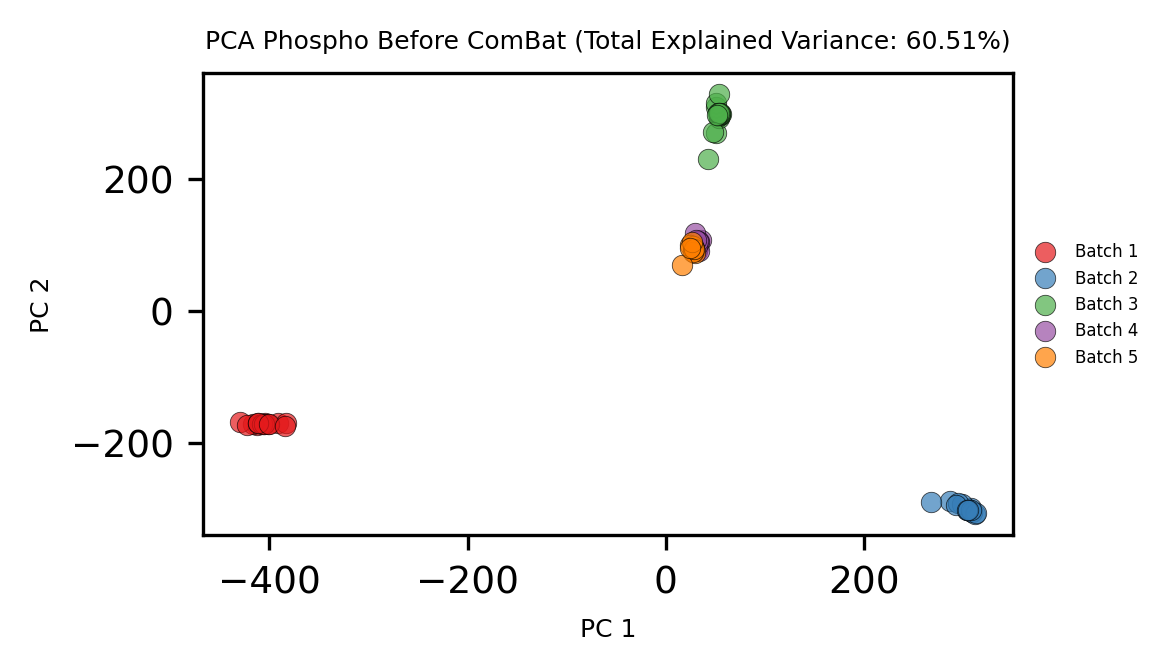

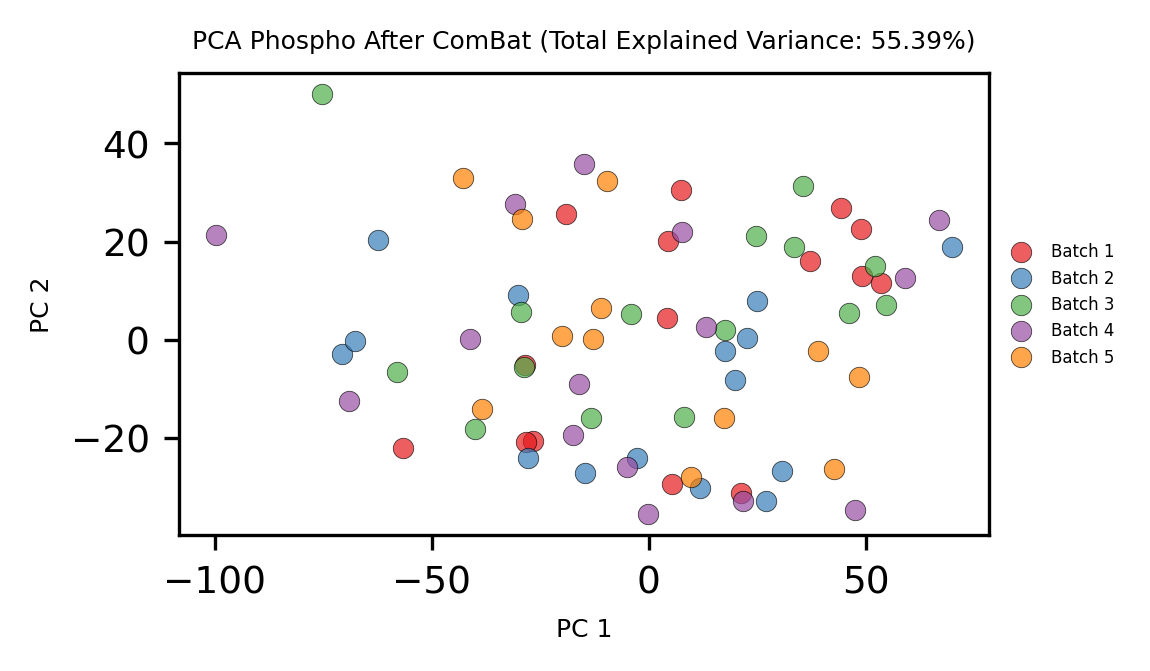

In [4]:
experiment_name_RatioBeforeC = "PCA Phospho Before ComBat"
grouping = "Batch"

PCA2d(
    experiment_name=experiment_name_RatioBeforeC,
    model_file=model_location,  # Excel
    tsv_file=df_NoNorm_BeforeC,          # TSV
    grouping=grouping,
    legend_position='right',
    rename_dict=sampleName_Dict,
    legend_ncol=1,
    fixed_size=(4, 2)
)


experiment_name_RatioBeforeC = "PCA Phospho After ComBat"
grouping = "Batch"

PCA2d(
    experiment_name=experiment_name_RatioBeforeC,
    model_file=model_location,  # Excel
    tsv_file=df_AfterC,          # TSV
    grouping=grouping,
    legend_position='right',
    rename_dict=sampleName_Dict,
    legend_ncol=1,
    fixed_size=(4, 2)
)





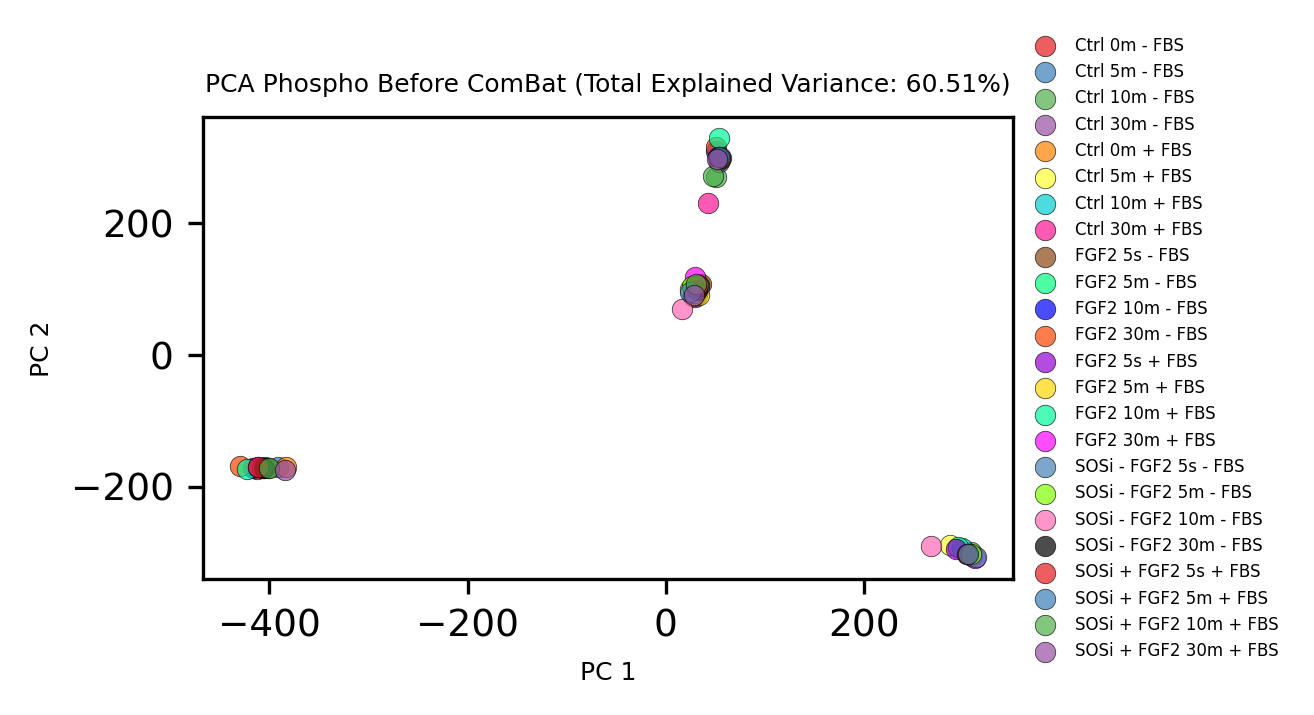

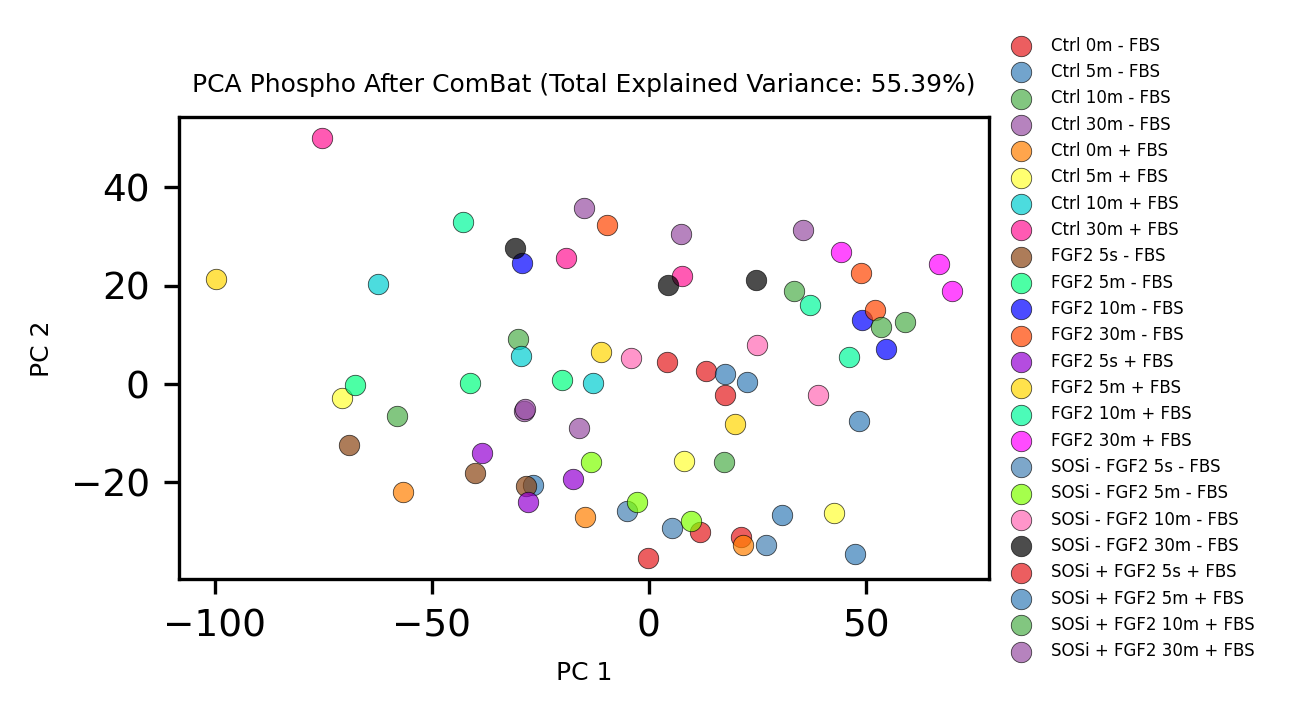

In [5]:
experiment_name_RatioBeforeC = "PCA Phospho Before ComBat"
grouping = "Condition"

PCA2d(
    experiment_name=experiment_name_RatioBeforeC,
    model_file=model_location,  # Excel
    tsv_file=df_NoNorm_BeforeC,          # TSV
    grouping=grouping,
    legend_position='right',
    rename_dict=sampleName_Dict,
    legend_ncol=1,
    fixed_size=(4, 2)
)


experiment_name_RatioBeforeC = "PCA Phospho After ComBat"
grouping = "Condition"

PCA2d(
    experiment_name=experiment_name_RatioBeforeC,
    model_file=model_location,  # Excel
    tsv_file=df_AfterC,          # TSV
    grouping=grouping,
    legend_position='right',
    rename_dict=sampleName_Dict,
    legend_ncol=1,
    fixed_size=(4, 2)
)


#### Normal Proteome

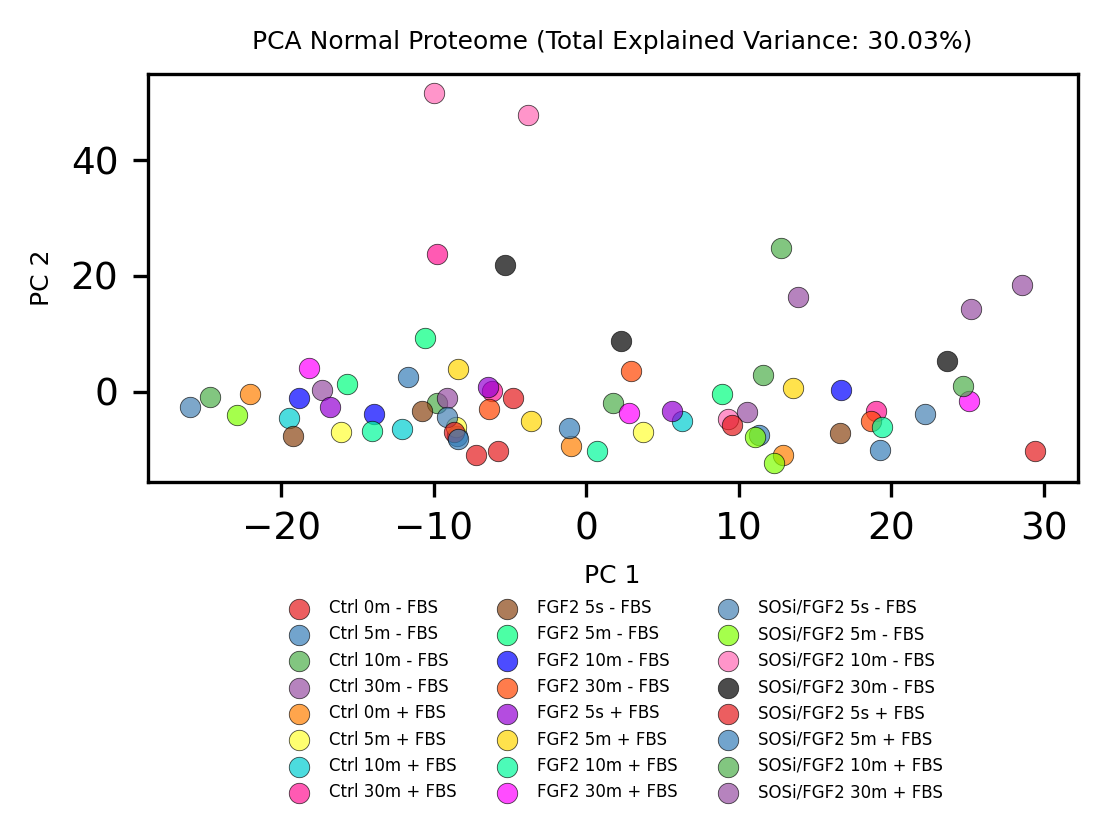

In [6]:
# Batch is not existent in the normal proteome!!!!

experiment_name_RatioBeforeC = "PCA Normal Proteome"
grouping = "Time"

PCA2d(
    experiment_name=experiment_name_RatioBeforeC,
    model_file=model_location,  # Excel
    tsv_file=df_np,          # TSV
    grouping=grouping,
    legend_position='bottom',
    rename_dict=sampleName_Dict,
    legend_ncol=3,
    fixed_size=(4, 2)
)


## UMAP

#### Phosphoproteome

c:\Users\Montoni\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Montoni\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


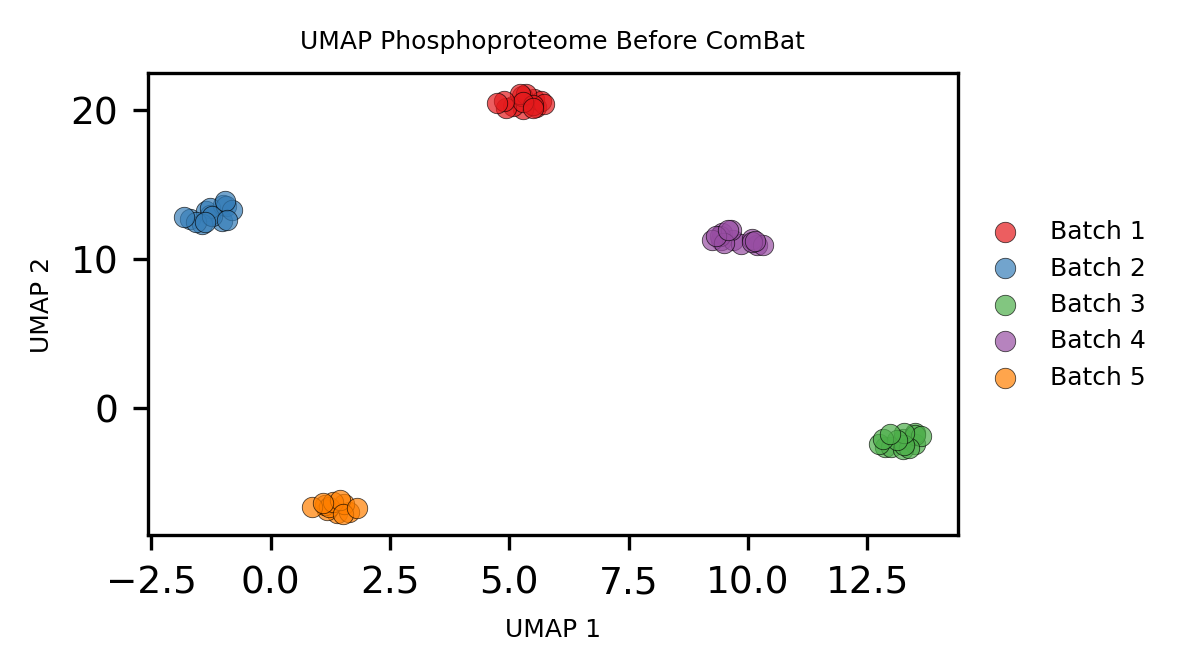

c:\Users\Montoni\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Montoni\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


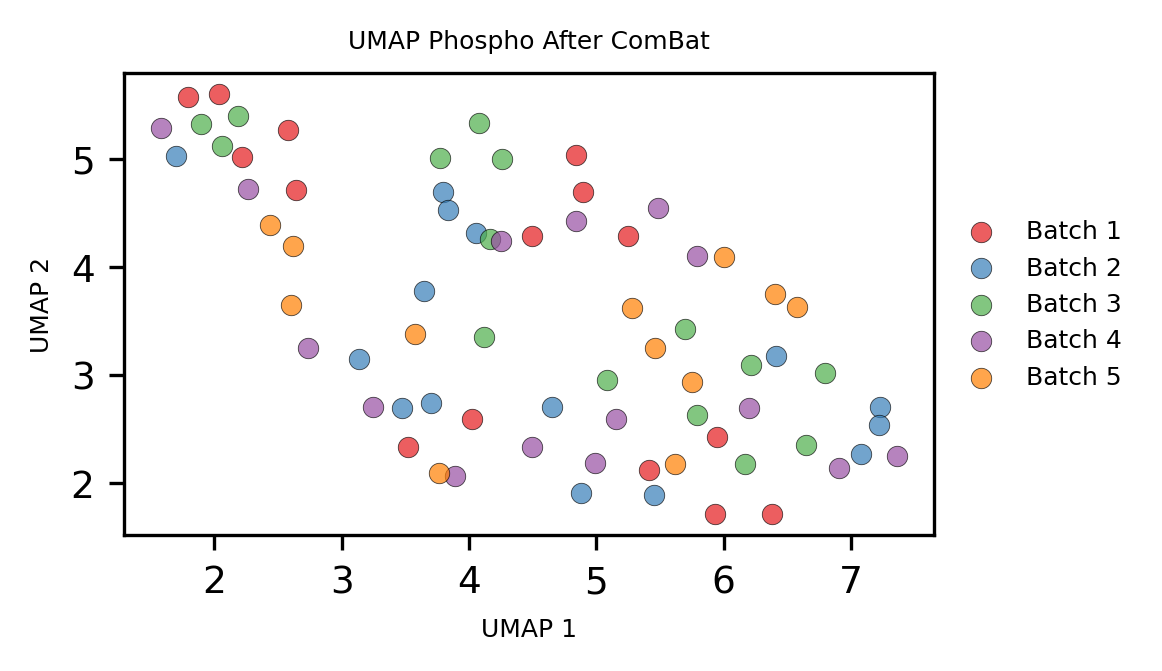

In [7]:
experiment_name_RatioBeforeC = "UMAP Phosphoproteome Before ComBat"
grouping = "Batch"

UMAP2d(
    experiment_name=experiment_name_RatioBeforeC,
    model_file=model_location,  # Excel
    tsv_file=df_NoNorm_BeforeC,          # TSV
    grouping=grouping,
    legend_position='right',
    rename_dict=sampleName_Dict,
    legend_ncol=1,
    fixed_size=(4, 2)
)


experiment_name_RatioBeforeC = "UMAP Phospho After ComBat"
grouping = "Batch"

UMAP2d(
    experiment_name=experiment_name_RatioBeforeC,
    model_file=model_location,  # Excel
    tsv_file=df_AfterC,          # TSV
    grouping=grouping,
    legend_position='right',
    rename_dict=sampleName_Dict,
    legend_ncol=1,
    fixed_size=(4, 2)
)

experiment_name_RatioBeforeC = "UMAP Phospho After ComBat"
grouping = "Condition"


c:\Users\Montoni\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Montoni\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


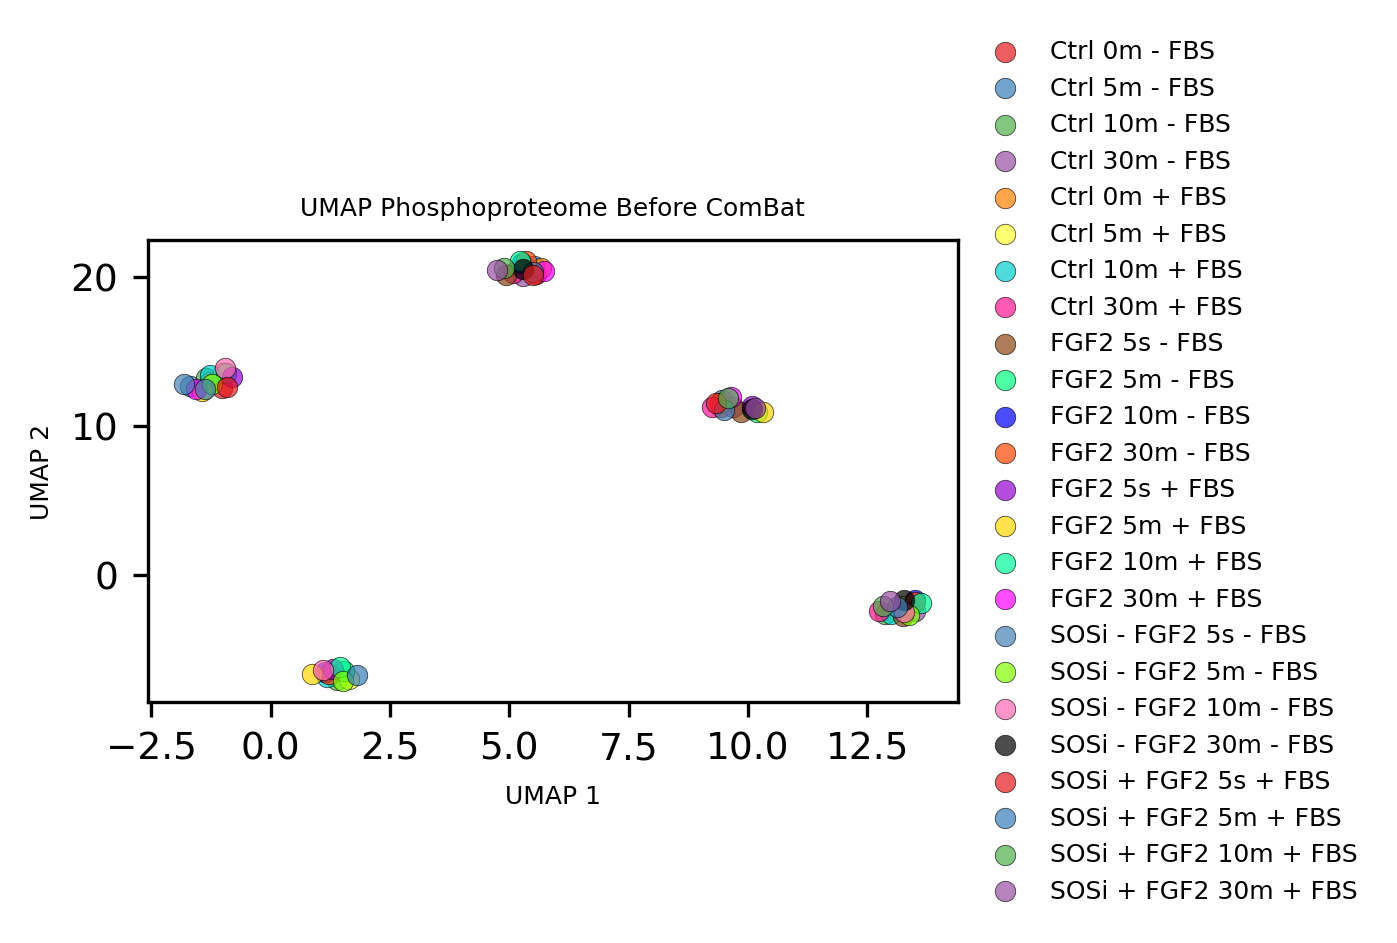

c:\Users\Montoni\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Montoni\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


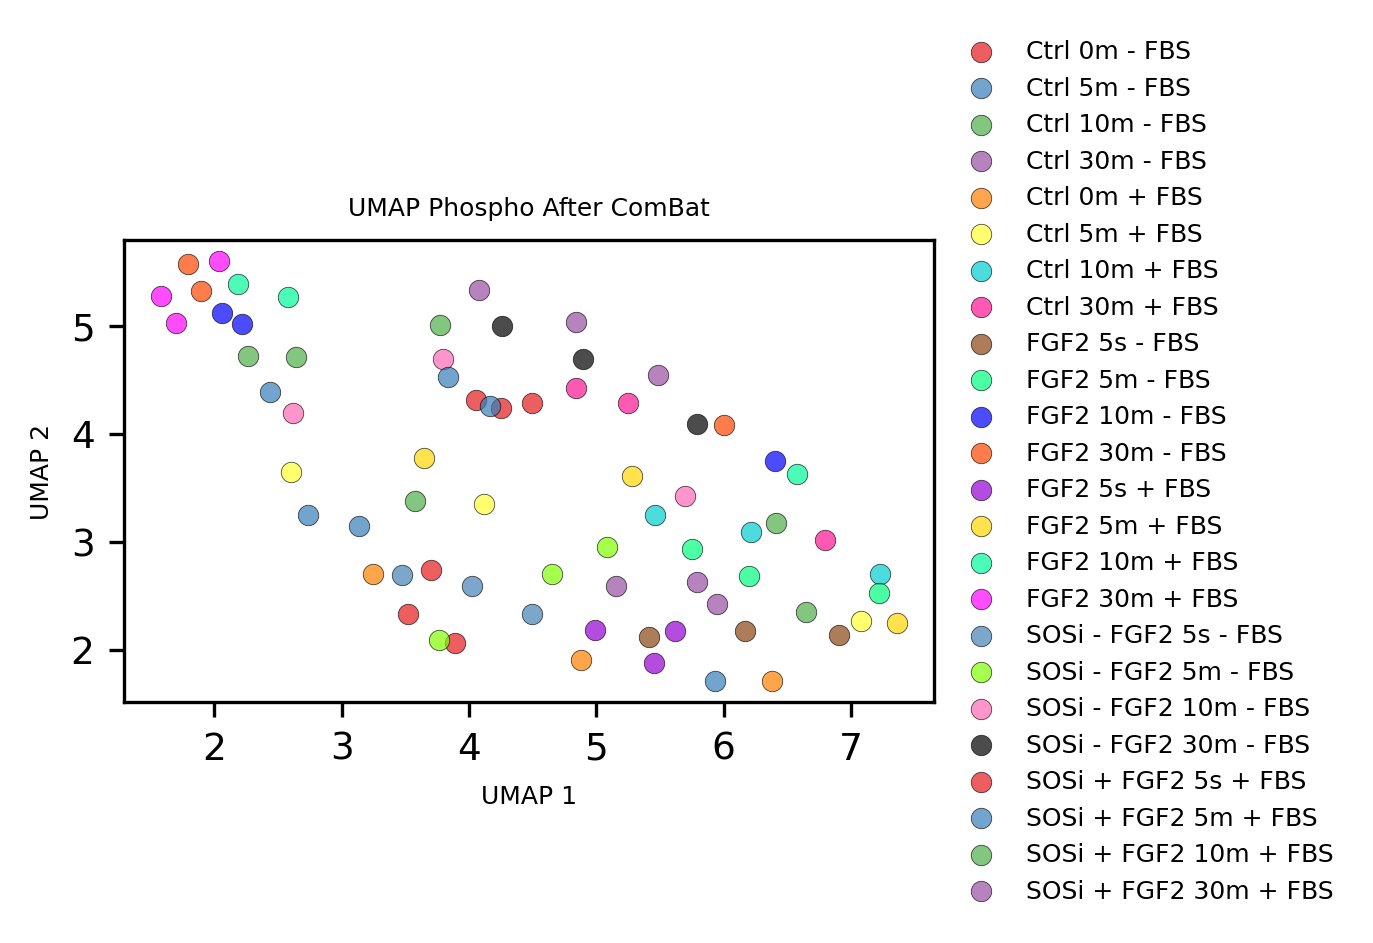

In [8]:
experiment_name_RatioBeforeC = "UMAP Phosphoproteome Before ComBat"
grouping = "Condition"

UMAP2d(
    experiment_name=experiment_name_RatioBeforeC,
    model_file=model_location,  # Excel
    tsv_file=df_NoNorm_BeforeC,          # TSV
    grouping=grouping,
    legend_position='right',
    rename_dict=sampleName_Dict,
    legend_ncol=1,
    fixed_size=(4, 2)
)


experiment_name_RatioBeforeC = "UMAP Phospho After ComBat"
grouping = "Condition"

UMAP2d(
    experiment_name=experiment_name_RatioBeforeC,
    model_file=model_location,  # Excel
    tsv_file=df_AfterC,          # TSV
    grouping=grouping,
    legend_position='right',
    rename_dict=sampleName_Dict,
    legend_ncol=1,
    fixed_size=(4, 2)
)

experiment_name_RatioBeforeC = "UMAP Phospho After ComBat"
grouping = "Condition"


#### Normal Proteome

c:\Users\Montoni\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\Montoni\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


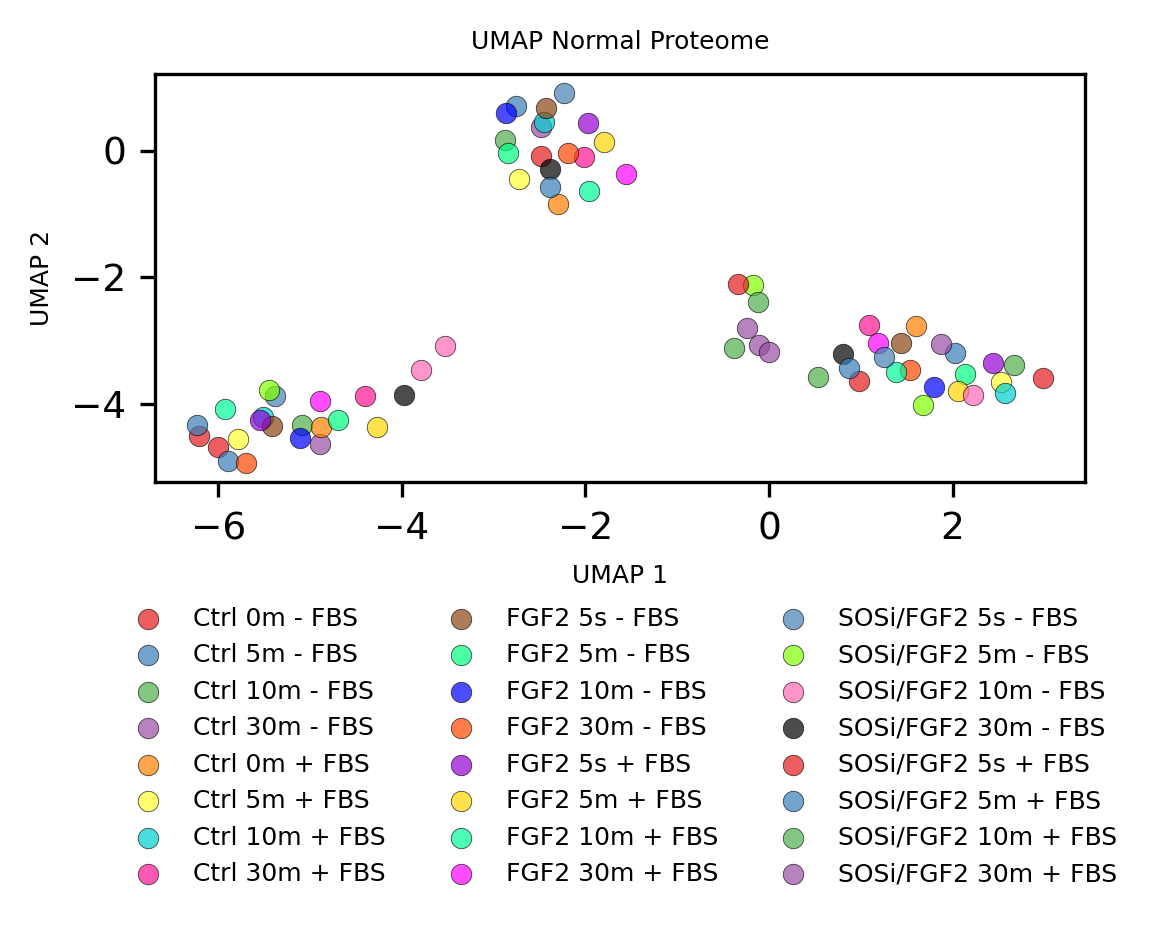

In [9]:
# Batch is not existent in the normal proteome!!!!

experiment_name_RatioBeforeC = "UMAP Normal Proteome"
grouping = "Time"

UMAP2d(
    experiment_name=experiment_name_RatioBeforeC,
    model_file=model_location,  # Excel
    tsv_file=df_np,          # TSV
    grouping=grouping,
    legend_position='bottom',
    rename_dict=sampleName_Dict,
    legend_ncol=3,
    fixed_size=(4, 2)
)
